master shape: (99441, 22)

First 3 months:
   purchase_month  orders   revenue  orders_mom_pct
0     2016-09-01       4    252.24             NaN
1     2016-10-01     324  59090.48     8000.000000
2     2016-12-01       1     19.62      -99.691358

Last 3 months:
    purchase_month  orders     revenue  orders_mom_pct
22     2018-08-01    6512  1022425.32        3.496503
23     2018-09-01      16     4439.54      -99.754300
24     2018-10-01       4      589.67      -75.000000

Peak month: 2017-11 with 7,544 orders


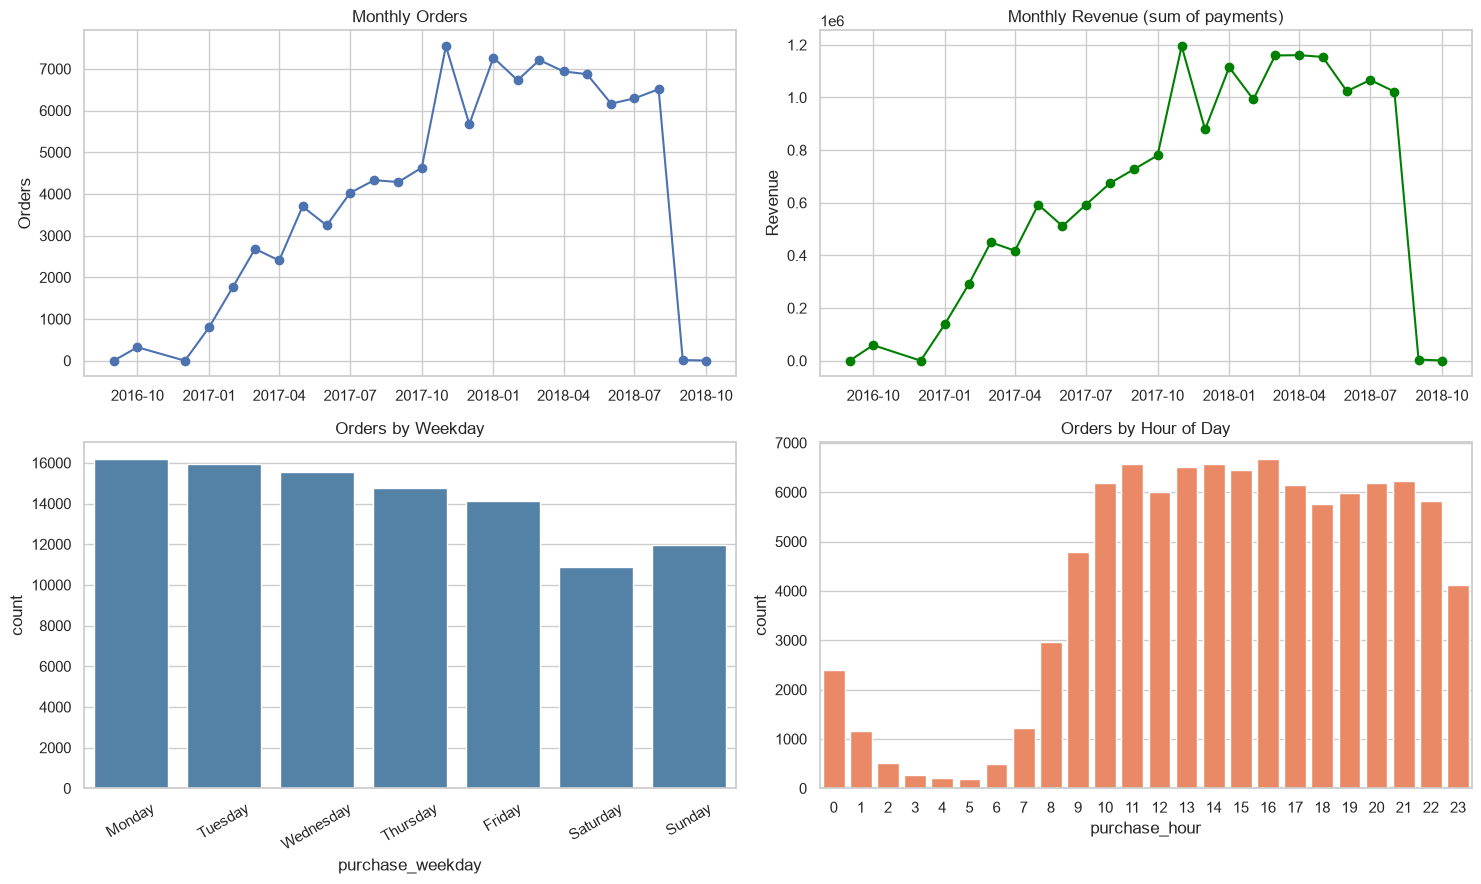

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
P = "../data/processed/"

# ---------- Load processed data ----------
# parse_dates re-converts the date columns that CSV stored as plain text
date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
orders = pd.read_csv(P + "orders.csv", parse_dates=date_cols)
customers = pd.read_csv(P + "customers.csv")
order_items = pd.read_csv(P + "order_items.csv")
payments_agg = pd.read_csv(P + "payments_agg.csv")
reviews_agg = pd.read_csv(P + "reviews_agg.csv")

# ---------- Aggregate order_items to one row per order ----------
items_agg = order_items.groupby("order_id").agg(
    item_count=("order_item_id", "size"),
    items_price=("price", "sum"),
    freight_total=("freight_value", "sum"),
    seller_count=("seller_id", "nunique"),
).reset_index()

# ---------- Build the master table (left merges keep every order) ----------
master = (
    orders
    .merge(customers[["customer_id", "customer_unique_id", "customer_state", "customer_city"]],
           on="customer_id", how="left")
    .merge(items_agg, on="order_id", how="left")
    .merge(payments_agg, on="order_id", how="left")
    .merge(reviews_agg, on="order_id", how="left")
)

print(f"master shape: {master.shape}")
assert len(master) == len(orders), "Row explosion! A merge duplicated orders."

# ---------- Monthly demand ----------
master["purchase_month"] = master["order_purchase_timestamp"].dt.to_period("M")
monthly = master.groupby("purchase_month").agg(
    orders=("order_id", "count"),
    revenue=("total_payment_value", "sum"),
).reset_index()
monthly["purchase_month"] = monthly["purchase_month"].dt.to_timestamp()
monthly["orders_mom_pct"] = monthly["orders"].pct_change() * 100

print("\nFirst 3 months:\n", monthly.head(3))
print("\nLast 3 months:\n", monthly.tail(3))
peak = monthly.loc[monthly["orders"].idxmax()]
print(f"\nPeak month: {peak['purchase_month'].strftime('%Y-%m')} with {int(peak['orders']):,} orders")

# ---------- Weekday and hour patterns ----------
master["purchase_weekday"] = master["order_purchase_timestamp"].dt.day_name()
master["purchase_hour"] = master["order_purchase_timestamp"].dt.hour
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# ---------- Charts ----------
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

axes[0, 0].plot(monthly["purchase_month"], monthly["orders"], marker="o")
axes[0, 0].set_title("Monthly Orders")
axes[0, 0].set_ylabel("Orders")

axes[0, 1].plot(monthly["purchase_month"], monthly["revenue"], marker="o", color="green")
axes[0, 1].set_title("Monthly Revenue (sum of payments)")
axes[0, 1].set_ylabel("Revenue")

sns.countplot(data=master, x="purchase_weekday", order=weekday_order, ax=axes[1, 0], color="steelblue")
axes[1, 0].set_title("Orders by Weekday")
axes[1, 0].tick_params(axis="x", rotation=30)

sns.countplot(data=master, x="purchase_hour", ax=axes[1, 1], color="coral")
axes[1, 1].set_title("Orders by Hour of Day")

plt.tight_layout()
plt.show()

Valid orders: 98,207 of 99,441

Unique customer_id        : 99,441
Unique customer_unique_id : 96,096

Unique customers (valid orders): 94,990
Repeat customers (2+ orders)   : 2,888 (3.04%)

Orders-per-customer distribution:
order_id
1     92102
2      2652
3       188
4        29
5         9
6         5
7         3
9         1
16        1
Name: count, dtype: int64

Top 10 states:
                orders  customers     revenue     aov  order_share_pct
customer_state                                                        
SP               41127      39749  5878935.99  142.95            41.88
RJ               12698      12242  2115994.28  166.64            12.93
MG               11496      11134  1843460.37  160.36            11.71
RS                5417       5234   877803.80  162.05             5.52
PR                4983       4825   794653.20  159.47             5.07
SC                3600       3502   608180.51  168.94             3.67
BA                3344       3244   607041.45  1

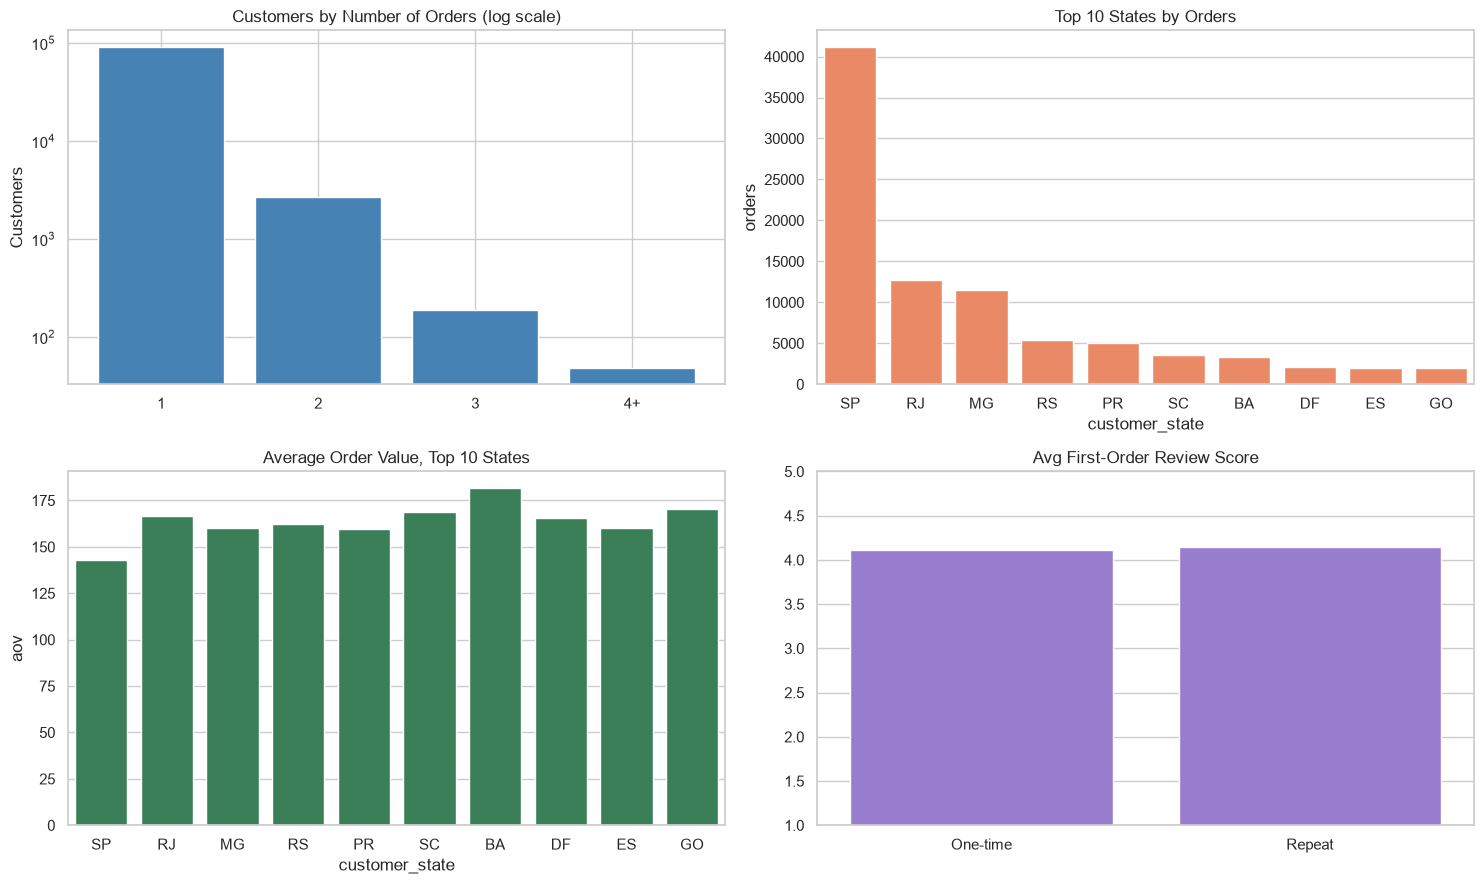

In [2]:
# ---------- Valid orders only (exclude canceled / unavailable) ----------
valid = master[~master["order_status"].isin(["canceled", "unavailable"])].copy()
print(f"Valid orders: {len(valid):,} of {len(master):,}")

# ---------- 1. Identity check: customer_id vs customer_unique_id ----------
print(f"\nUnique customer_id        : {master['customer_id'].nunique():,}")
print(f"Unique customer_unique_id : {master['customer_unique_id'].nunique():,}")

# ---------- 2. Orders per unique customer ----------
orders_per_customer = valid.groupby("customer_unique_id")["order_id"].nunique()
freq_dist = orders_per_customer.value_counts().sort_index()
repeat_rate = (orders_per_customer > 1).mean() * 100

print(f"\nUnique customers (valid orders): {len(orders_per_customer):,}")
print(f"Repeat customers (2+ orders)   : {(orders_per_customer > 1).sum():,} ({repeat_rate:.2f}%)")
print("\nOrders-per-customer distribution:")
print(freq_dist)

# ---------- 3. State-wise behaviour ----------
state_stats = valid.groupby("customer_state").agg(
    orders=("order_id", "count"),
    customers=("customer_unique_id", "nunique"),
    revenue=("total_payment_value", "sum"),
    aov=("total_payment_value", "mean"),
).sort_values("orders", ascending=False)
state_stats["order_share_pct"] = state_stats["orders"] / state_stats["orders"].sum() * 100

print("\nTop 10 states:")
print(state_stats.head(10).round(2))
print(f"\nTop 3 states share of orders: {state_stats['order_share_pct'].head(3).sum():.1f}%")

# ---------- 4. Does the FIRST order's review score predict a return? ----------
first_orders = (
    valid.sort_values("order_purchase_timestamp")
         .drop_duplicates(subset="customer_unique_id", keep="first")
         .copy()
)
first_orders["is_repeat"] = first_orders["customer_unique_id"].map(orders_per_customer) > 1

review_cmp = first_orders.groupby("is_repeat")["review_score"].agg(["mean", "count"]).round(3)
print("\nFirst-order review score: repeat vs one-time customers")
print(review_cmp)

# ---------- Charts ----------
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# (a) orders per customer, capped at 4+
capped = orders_per_customer.clip(upper=4).value_counts().sort_index()
capped.index = ["1", "2", "3", "4+"][: len(capped)]
axes[0, 0].bar(capped.index, capped.values, color="steelblue")
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Customers by Number of Orders (log scale)")
axes[0, 0].set_ylabel("Customers")

# (b) top 10 states by orders
top_states = state_stats.head(10)
sns.barplot(x=top_states.index, y=top_states["orders"], ax=axes[0, 1], color="coral")
axes[0, 1].set_title("Top 10 States by Orders")

# (c) AOV for the same top 10 states
sns.barplot(x=top_states.index, y=top_states["aov"], ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Average Order Value, Top 10 States")

# (d) first-order review score, repeat vs one-time
sns.barplot(x=["One-time", "Repeat"], y=review_cmp["mean"].values, ax=axes[1, 1], color="mediumpurple")
axes[1, 1].set_ylim(1, 5)
axes[1, 1].set_title("Avg First-Order Review Score")

plt.tight_layout()
plt.show()

Delivered orders analysed: 96,470  (Phase 1 expected 96,470)

Late deliveries: 6,534 (6.77%)  (Phase 1 expected 6.77%)

Delivery days:
count    96470.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63
Name: delivery_days, dtype: float64

Percentiles (days):
0.50    10.2
0.90    23.1
0.95    29.3
Name: delivery_days, dtype: float64
Average promised window: 23.7 days

When late, median delay: 7 days
Late by more than 7 days: 2,862 orders

Median days per stage:
approval_days    0.01
handling_days    1.85
transit_days     7.11
dtype: float64

Worst 5 states by late %:
                orders  median_days  late_rate  late_pct
customer_state                                          
AL                 397        22.33       0.21     21.41
MA                 717        19.19       0.17     17.43
SE                 335        18.01       0.15     15.22
PI                 476        16.29       0.14     13.87
CE      

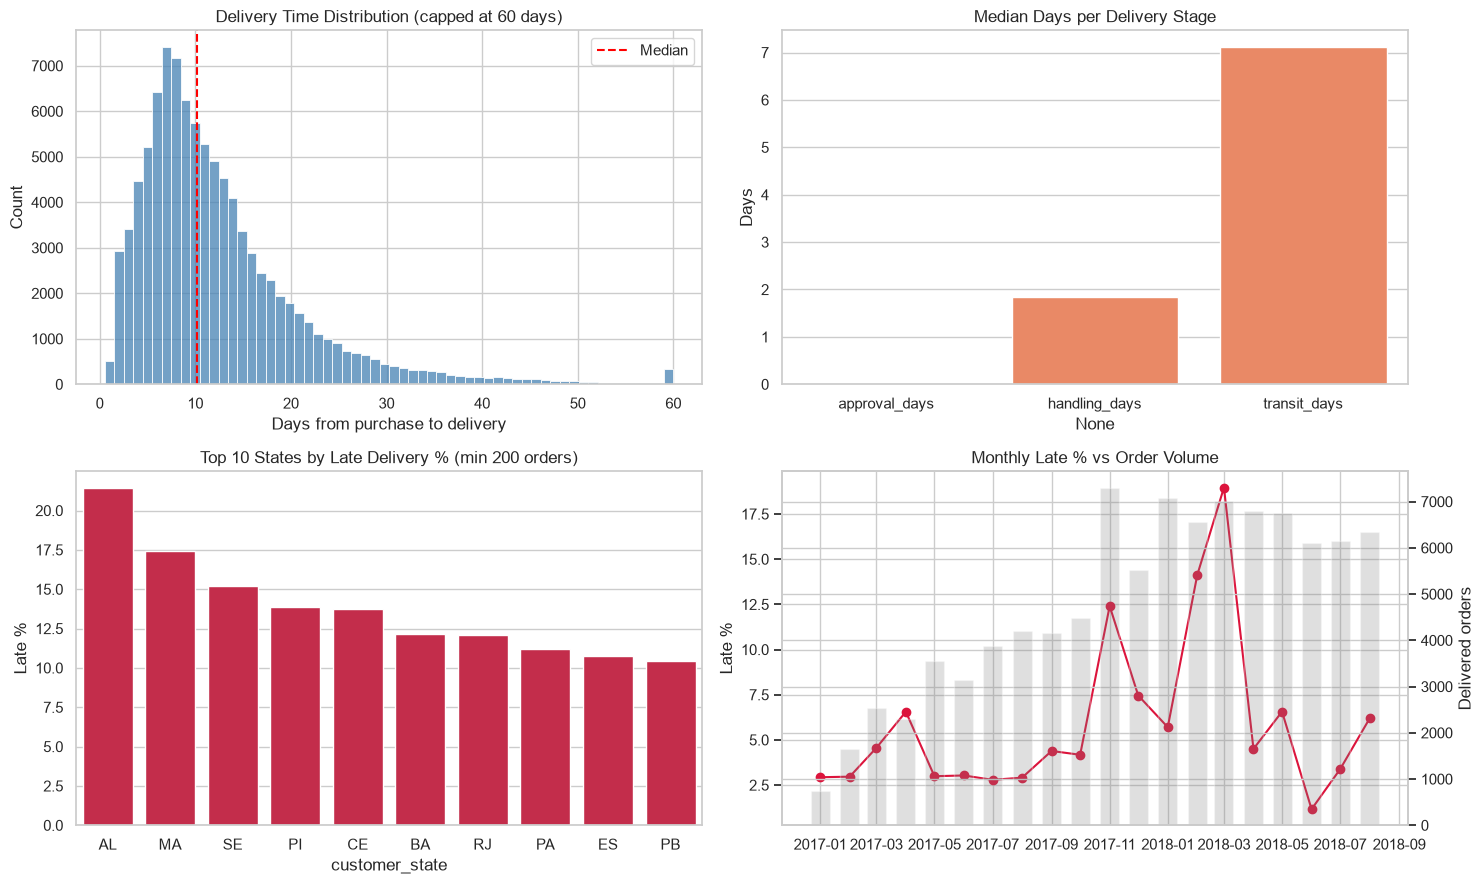

In [3]:
# ---------- Delivered orders with a delivery date ----------
delivered = master[
    (master["order_status"] == "delivered")
    & master["order_delivered_customer_date"].notna()
].copy()
print(f"Delivered orders analysed: {len(delivered):,}  (Phase 1 expected 96,470)")

# ---------- Core delivery metrics ----------
delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivered["estimated_days"] = (
    delivered["order_estimated_delivery_date"] - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Date-level delay (same method as Phase 1): positive = late
delivered["delay_days"] = (
    delivered["order_delivered_customer_date"].dt.normalize()
    - delivered["order_estimated_delivery_date"].dt.normalize()
).dt.days
delivered["is_late"] = delivered["delay_days"] > 0

late_rate = delivered["is_late"].mean() * 100
print(f"\nLate deliveries: {delivered['is_late'].sum():,} ({late_rate:.2f}%)  (Phase 1 expected 6.77%)")

# ---------- Delivery time distribution ----------
print("\nDelivery days:")
print(delivered["delivery_days"].describe().round(2))
print("\nPercentiles (days):")
print(delivered["delivery_days"].quantile([0.5, 0.9, 0.95]).round(1))
print(f"Average promised window: {delivered['estimated_days'].mean():.1f} days")

late_only = delivered[delivered["is_late"]]
print(f"\nWhen late, median delay: {late_only['delay_days'].median():.0f} days")
print(f"Late by more than 7 days: {(late_only['delay_days'] > 7).sum():,} orders")

# ---------- Stage-wise breakdown (exclude timeline-violation rows) ----------
clean_t = delivered[~delivered["has_timeline_violation"]].copy()
clean_t["approval_days"] = (
    clean_t["order_approved_at"] - clean_t["order_purchase_timestamp"]
).dt.total_seconds() / 86400
clean_t["handling_days"] = (
    clean_t["order_delivered_carrier_date"] - clean_t["order_approved_at"]
).dt.total_seconds() / 86400
clean_t["transit_days"] = (
    clean_t["order_delivered_customer_date"] - clean_t["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

stage_median = clean_t[["approval_days", "handling_days", "transit_days"]].median().round(2)
print("\nMedian days per stage:")
print(stage_median)

# ---------- State-wise performance (only states with enough orders) ----------
state_perf = delivered.groupby("customer_state").agg(
    orders=("order_id", "count"),
    median_days=("delivery_days", "median"),
    late_rate=("is_late", "mean"),
)
state_perf["late_pct"] = state_perf["late_rate"] * 100
state_perf = state_perf[state_perf["orders"] >= 200].sort_values("late_pct", ascending=False)

print("\nWorst 5 states by late %:")
print(state_perf.head(5).round(2))
print("\nBest 5 states by late %:")
print(state_perf.tail(5).round(2))

# ---------- Month-wise late rate (skip months with tiny volume) ----------
monthly_delivery = delivered.groupby("purchase_month").agg(
    orders=("order_id", "count"),
    late_rate=("is_late", "mean"),
)
monthly_delivery["late_pct"] = monthly_delivery["late_rate"] * 100
monthly_delivery = monthly_delivery[monthly_delivery["orders"] >= 500]
monthly_delivery.index = monthly_delivery.index.to_timestamp()

worst_month = monthly_delivery["late_pct"].idxmax()
print(f"\nWorst month: {worst_month.strftime('%Y-%m')} with {monthly_delivery['late_pct'].max():.1f}% late")

# ---------- Charts ----------
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# (a) delivery time distribution, capped at 60 days so outliers don't squash the chart
sns.histplot(delivered["delivery_days"].clip(upper=60), bins=60, ax=axes[0, 0], color="steelblue")
axes[0, 0].axvline(delivered["delivery_days"].median(), color="red", linestyle="--", label="Median")
axes[0, 0].set_title("Delivery Time Distribution (capped at 60 days)")
axes[0, 0].set_xlabel("Days from purchase to delivery")
axes[0, 0].legend()

# (b) median days per stage
sns.barplot(x=stage_median.index, y=stage_median.values, ax=axes[0, 1], color="coral")
axes[0, 1].set_title("Median Days per Delivery Stage")
axes[0, 1].set_ylabel("Days")

# (c) worst 10 states by late %
worst10 = state_perf.head(10)
sns.barplot(x=worst10.index, y=worst10["late_pct"], ax=axes[1, 0], color="crimson")
axes[1, 0].set_title("Top 10 States by Late Delivery % (min 200 orders)")
axes[1, 0].set_ylabel("Late %")

# (d) monthly late % with order volume as faint bars behind it
ax = axes[1, 1]
ax.plot(monthly_delivery.index, monthly_delivery["late_pct"], marker="o", color="crimson")
ax.set_ylabel("Late %")
ax.set_title("Monthly Late % vs Order Volume")
ax2 = ax.twinx()
ax2.bar(monthly_delivery.index, monthly_delivery["orders"], width=20, alpha=0.25, color="gray")
ax2.set_ylabel("Delivered orders")

plt.tight_layout()
plt.show()